# Regression Tree — When is Both better than Amb only?

Predict delta = mort_both - mort_amb. Negative = both is better.

In [1]:
import sys
from pathlib import Path
_root = Path(".").resolve()
while not (_root / "paths.py").exists():
    _root = _root.parent
sys.path.insert(0, str(_root))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier, plot_tree
from sklearn.model_selection import cross_val_score, cross_val_predict
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

RESULTS_PATH = _root / "data_cluster" / "saltelli_with_wrong_pooling_columns" / "results.csv"
df = pd.read_csv(RESULTS_PATH)
print(f"Loaded {len(df)} runs")

UNCERTAINTIES = ["ccp_r1_same_bn_min", "ccp_r1_inter_bn_min", "bcas_rate", "waves_per_day", "wave_duration_min"]

amb  = df[(df["facility_eligibility"] == 0) & (df["ambulance_eligibility"] == 1)].sort_values("scenario").reset_index(drop=True)
both = df[(df["facility_eligibility"] == 1) & (df["ambulance_eligibility"] == 1)].sort_values("scenario").reset_index(drop=True)
assert (amb["scenario"].values == both["scenario"].values).all()

delta = both["death_rate_T1_BCAS"].values - amb["death_rate_T1_BCAS"].values
X = amb[UNCERTAINTIES].astype(float)

print(f"Scenarios: {len(delta)}")
print(f"Delta range: {delta.min():.4f} to {delta.max():.4f}")
print(f"Both better (delta < -0.01): {(delta < -0.01).sum()} ({(delta < -0.01).mean():.1%})")
print(f"Neutral (|delta| <= 0.01): {((delta >= -0.01) & (delta <= 0.01)).sum()}")
print(f"Both worse (delta > 0.01): {(delta > 0.01).sum()} ({(delta > 0.01).mean():.1%})")

Loaded 98304 runs
Scenarios: 24576
Delta range: -0.6667 to 0.4000
Both better (delta < -0.01): 6626 (27.0%)
Neutral (|delta| <= 0.01): 16444
Both worse (delta > 0.01): 1506 (6.1%)


## Regression Tree — Predict delta magnitude

depth= 1: R²=0.0973 ± 0.0238


depth= 2: R²=0.1720 ± 0.0282


depth= 3: R²=0.2147 ± 0.0257


depth= 4: R²=0.2378 ± 0.0248


depth= 5: R²=0.2670 ± 0.0234


...

depth=11: R²=0.2789 ± 0.0285


depth=12: R²=0.2755 ± 0.0276


depth=13: R²=0.2714 ± 0.0298


depth=14: R²=0.2689 ± 0.0301


depth=15: R²=0.2676 ± 0.0305


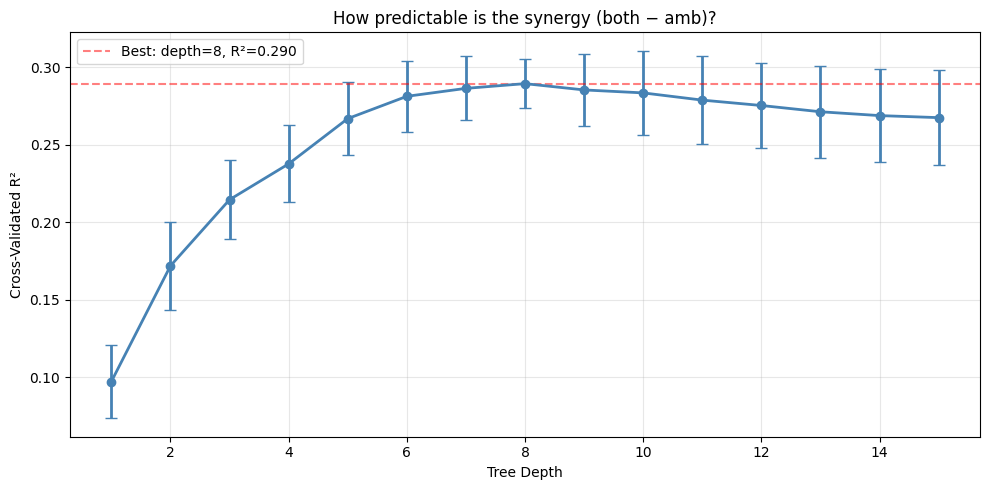


Best depth: 8, R² = 0.2896


In [2]:
depths = list(range(1, 16))
cv_means = []
cv_stds = []

for d in depths:
    tree = DecisionTreeRegressor(max_depth=d, min_samples_leaf=20, random_state=42)
    scores = cross_val_score(tree, X, delta, cv=10, scoring="r2")
    cv_means.append(scores.mean())
    cv_stds.append(scores.std())
    print(f"depth={d:2d}: R²={scores.mean():.4f} ± {scores.std():.4f}")

fig, ax = plt.subplots(figsize=(10, 5))
ax.errorbar(depths, cv_means, yerr=cv_stds, capsize=4, marker="o", color="steelblue", linewidth=2)
ax.set_xlabel("Tree Depth")
ax.set_ylabel("Cross-Validated R²")
ax.set_title("How predictable is the synergy (both − amb)?")
ax.grid(True, alpha=0.3)

best_d = depths[np.argmax(cv_means)]
best_r2 = max(cv_means)
ax.axhline(best_r2, color="red", linestyle="--", alpha=0.5, label=f"Best: depth={best_d}, R²={best_r2:.3f}")
ax.legend()
plt.tight_layout()
plt.show()

print(f"\nBest depth: {best_d}, R² = {best_r2:.4f}")

## Best Tree Visualization

Train R² = 0.2506


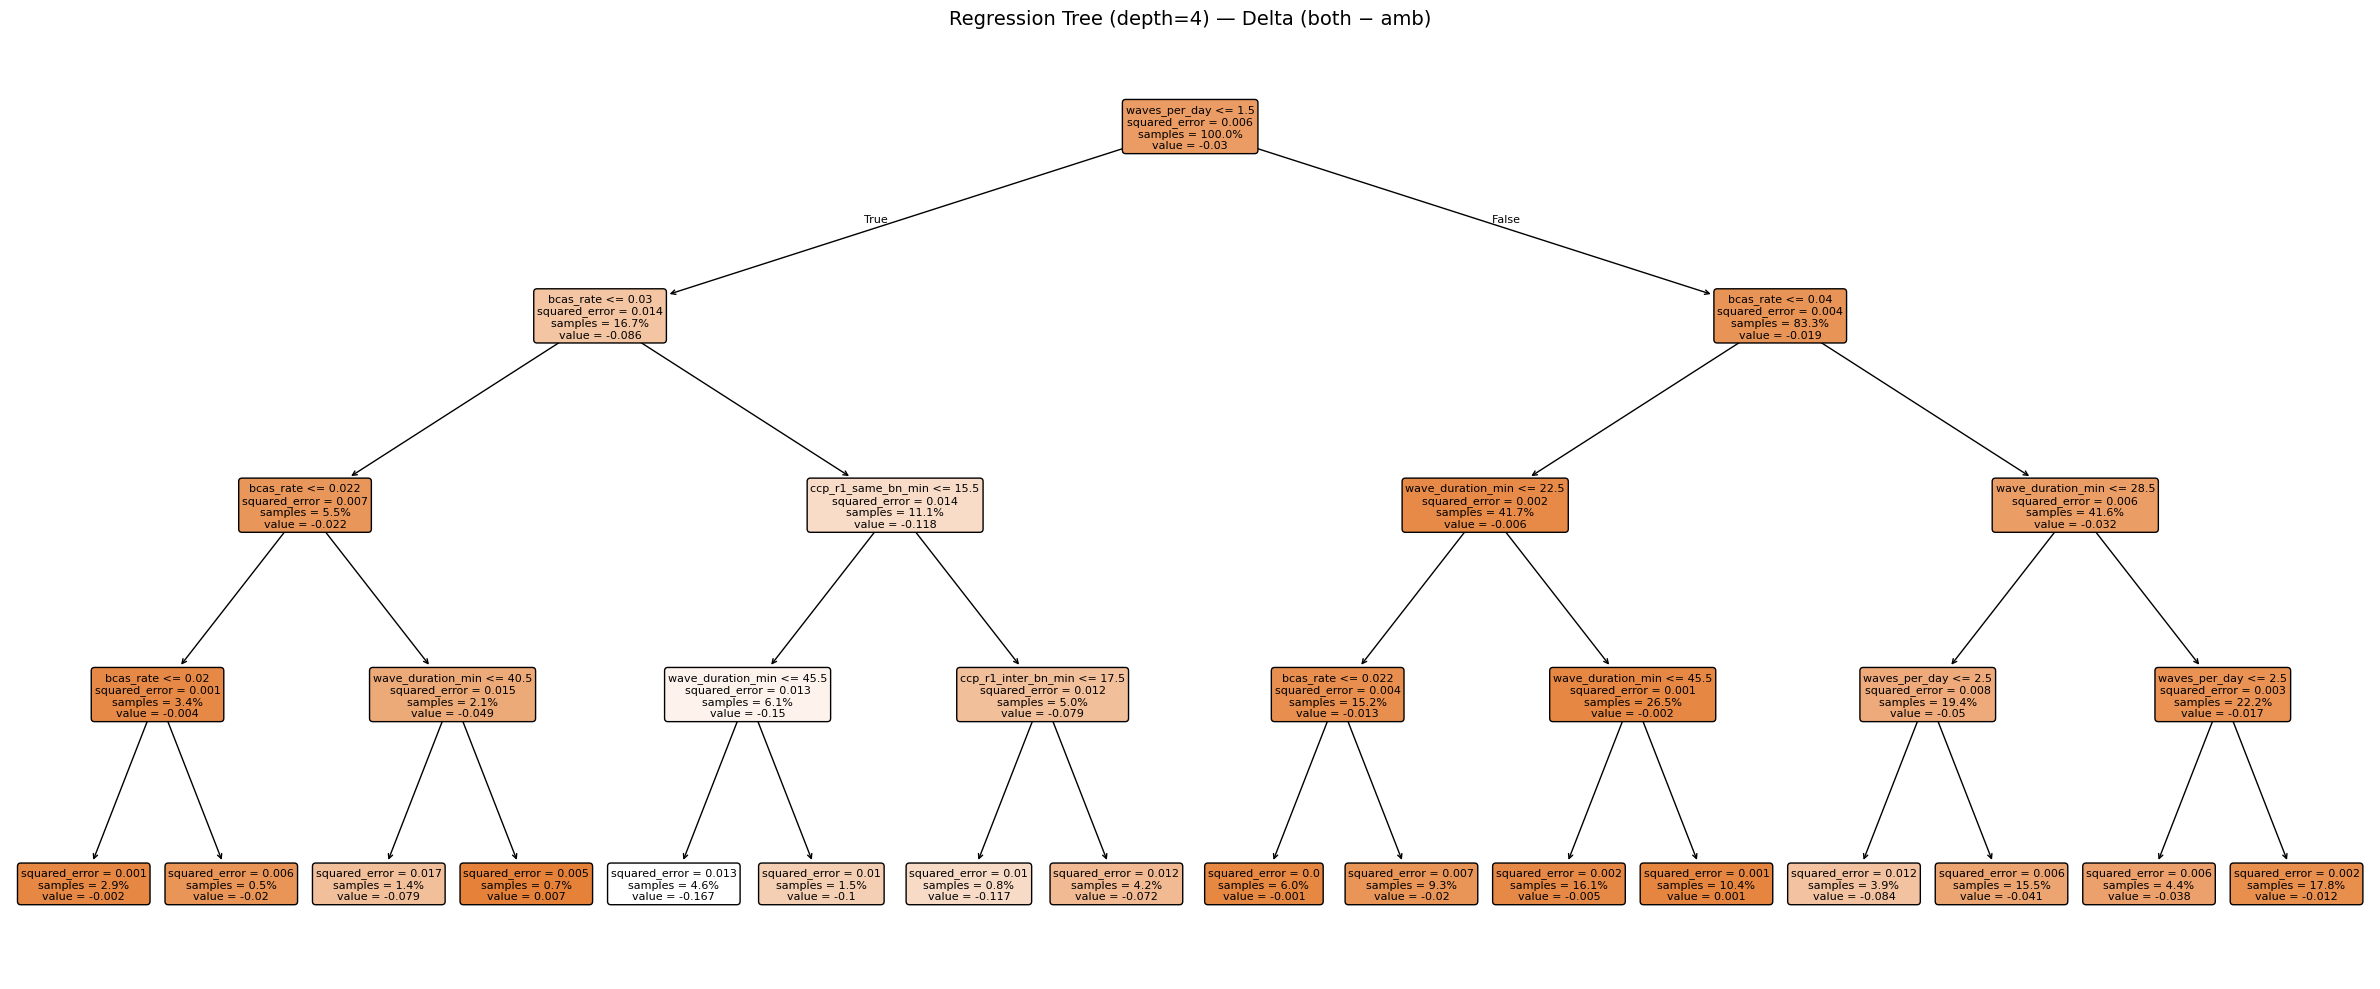

In [3]:
best_tree = DecisionTreeRegressor(max_depth=min(best_d, 4), min_samples_leaf=20, random_state=42)
best_tree.fit(X, delta)
print(f"Train R² = {best_tree.score(X, delta):.4f}")

fig, ax = plt.subplots(figsize=(24, 10))
plot_tree(best_tree, feature_names=UNCERTAINTIES, filled=True, rounded=True,
          fontsize=8, ax=ax, proportion=True)
ax.set_title(f"Regression Tree (depth={min(best_d, 4)}) — Delta (both − amb)", fontsize=14)
plt.tight_layout()
plt.show()

## Feature Importance

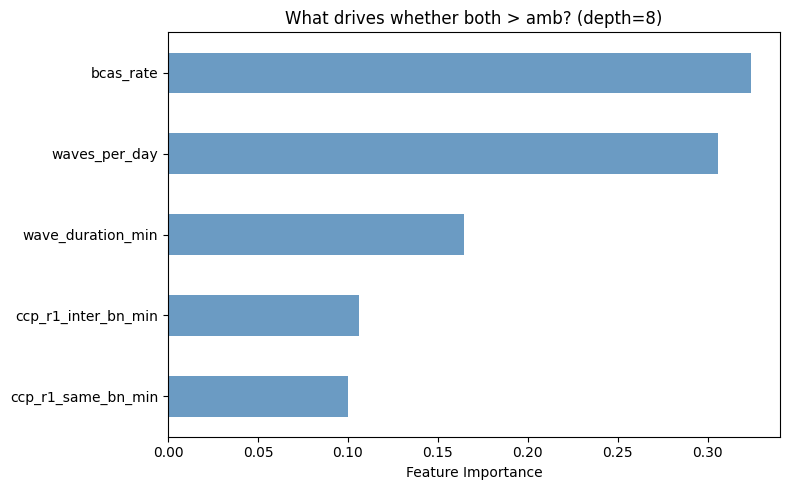

bcas_rate             0.3239
waves_per_day         0.3058
wave_duration_min     0.1646
ccp_r1_inter_bn_min   0.1059
ccp_r1_same_bn_min    0.0998


In [4]:
best_tree_full = DecisionTreeRegressor(max_depth=best_d, min_samples_leaf=20, random_state=42)
best_tree_full.fit(X, delta)

imp = pd.Series(best_tree_full.feature_importances_, index=UNCERTAINTIES).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 5))
imp.plot.barh(ax=ax, color="steelblue", alpha=0.8)
ax.set_xlabel("Feature Importance")
ax.set_title(f"What drives whether both > amb? (depth={best_d})")
plt.tight_layout()
plt.show()

print(imp.sort_values(ascending=False).to_string(float_format="%.4f"))

## Classification Tree — Both better vs not

Both better: 6626 / 24576 (27.0%)



Classification Tree depth=3
CV accuracy: 0.785 ± 0.008
              precision    recall  f1-score   support

  Not better       0.83      0.89      0.86     17950
 Both better       0.63      0.50      0.56      6626

    accuracy                           0.79     24576
   macro avg       0.73      0.69      0.71     24576
weighted avg       0.77      0.79      0.78     24576



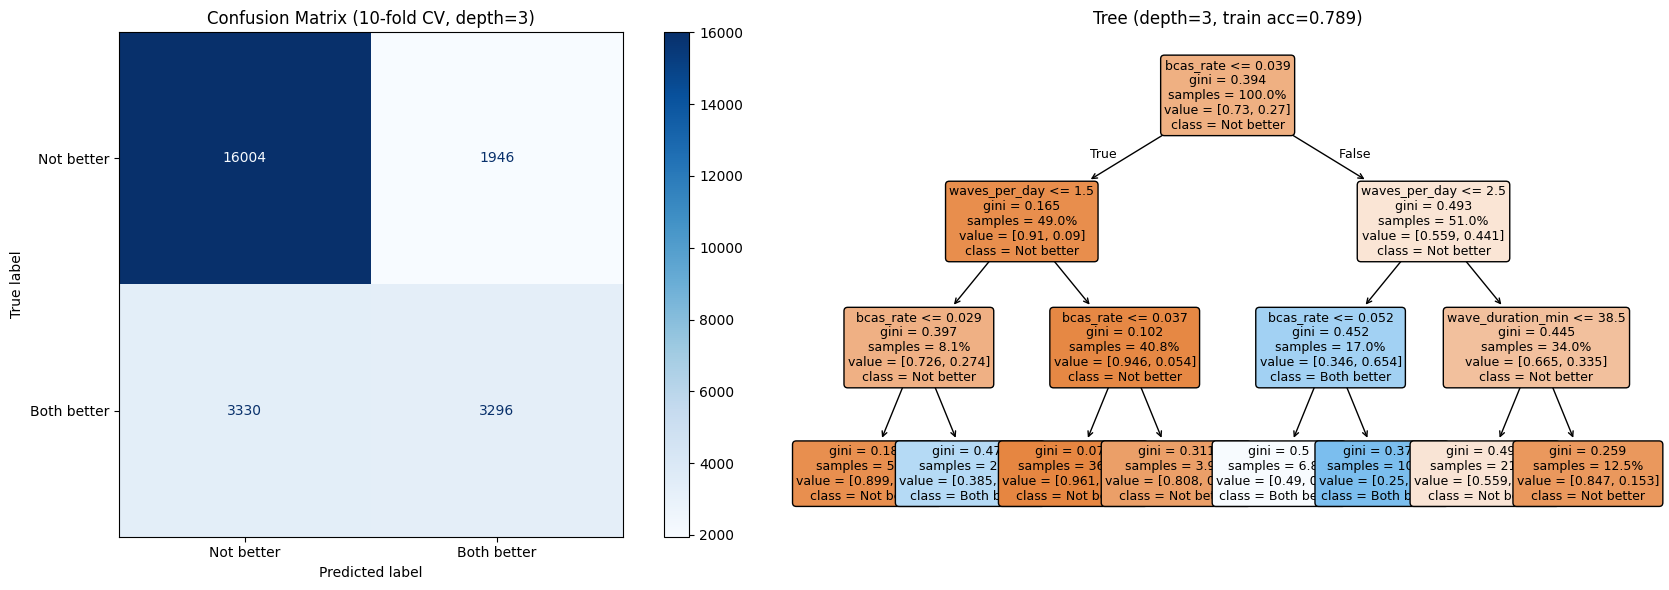

Feature importance:
bcas_rate             0.6437
waves_per_day         0.2472
wave_duration_min     0.1091
ccp_r1_same_bn_min    0.0000
ccp_r1_inter_bn_min   0.0000



Classification Tree depth=4
CV accuracy: 0.804 ± 0.006
              precision    recall  f1-score   support

  Not better       0.85      0.88      0.87     17950
 Both better       0.65      0.59      0.62      6626

    accuracy                           0.80     24576
   macro avg       0.75      0.74      0.74     24576
weighted avg       0.80      0.80      0.80     24576



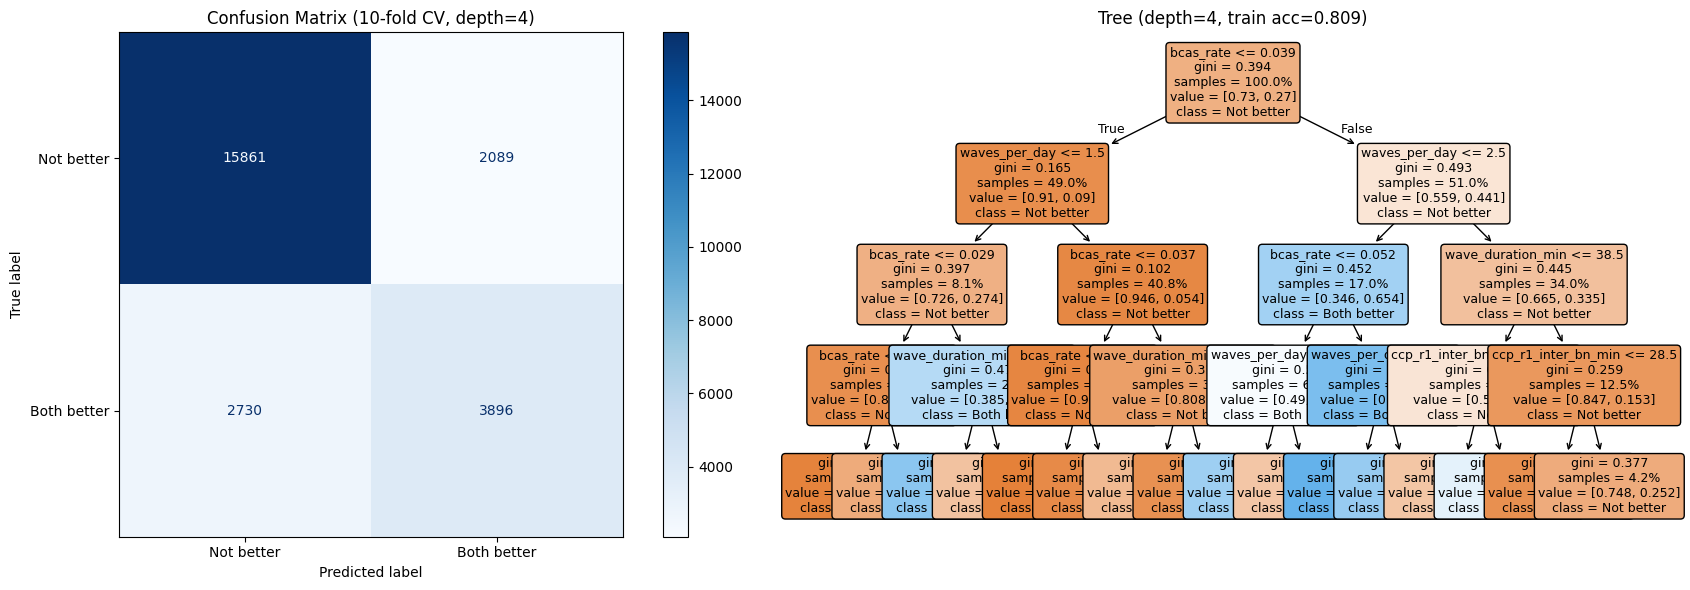

Feature importance:
bcas_rate             0.5960
waves_per_day         0.2544
wave_duration_min     0.1138
ccp_r1_inter_bn_min   0.0358
ccp_r1_same_bn_min    0.0000



Classification Tree depth=5
CV accuracy: 0.810 ± 0.007
              precision    recall  f1-score   support

  Not better       0.84      0.92      0.88     17950
 Both better       0.70      0.51      0.59      6626

    accuracy                           0.81     24576
   macro avg       0.77      0.72      0.73     24576
weighted avg       0.80      0.81      0.80     24576



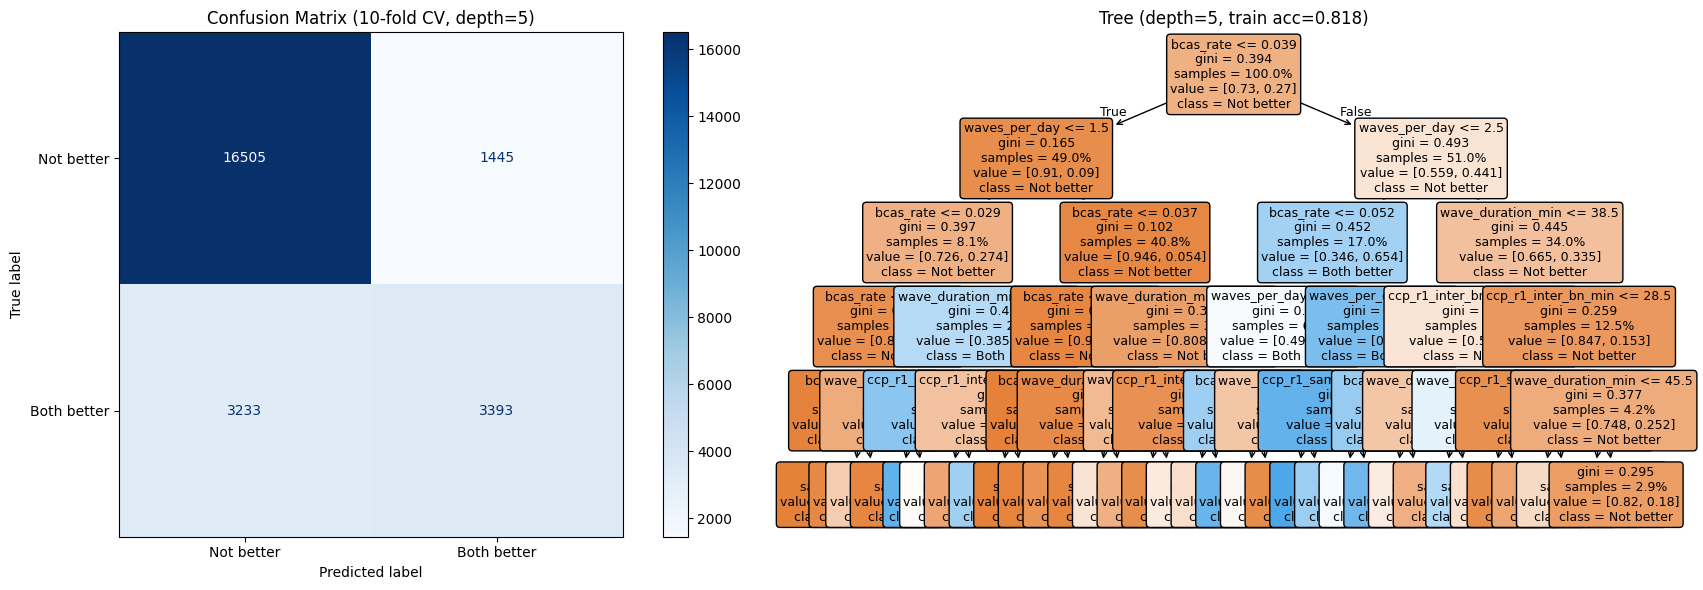

Feature importance:
bcas_rate             0.5564
waves_per_day         0.2266
wave_duration_min     0.1600
ccp_r1_inter_bn_min   0.0372
ccp_r1_same_bn_min    0.0197


In [5]:
y_class = (delta < -0.01).astype(int)  # 1 = both is better
print(f"Both better: {y_class.sum()} / {len(y_class)} ({y_class.mean():.1%})")

for depth in [3, 4, 5]:
    clf = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=20, random_state=42)
    cv_scores = cross_val_score(clf, X, y_class, cv=10, scoring="accuracy")
    y_pred = cross_val_predict(clf, X, y_class, cv=10)

    print(f"\n{'='*60}")
    print(f"Classification Tree depth={depth}")
    print(f"{'='*60}")
    print(f"CV accuracy: {cv_scores.mean():.3f} ± {cv_scores.std():.3f}")
    print(classification_report(y_class, y_pred, target_names=["Not better", "Both better"]))

    fig, axes = plt.subplots(1, 2, figsize=(18, 6))
    cm = confusion_matrix(y_class, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=["Not better", "Both better"]).plot(ax=axes[0], cmap="Blues")
    axes[0].set_title(f"Confusion Matrix (10-fold CV, depth={depth})")

    clf.fit(X, y_class)
    plot_tree(clf, feature_names=UNCERTAINTIES, class_names=["Not better", "Both better"],
              filled=True, rounded=True, fontsize=9, ax=axes[1], proportion=True)
    axes[1].set_title(f"Tree (depth={depth}, train acc={clf.score(X, y_class):.3f})")
    plt.tight_layout()
    plt.show()

    imp_clf = pd.Series(clf.feature_importances_, index=UNCERTAINTIES).sort_values(ascending=False)
    print(f"Feature importance:")
    print(imp_clf.to_string(float_format="%.4f"))

## Predicted vs Actual

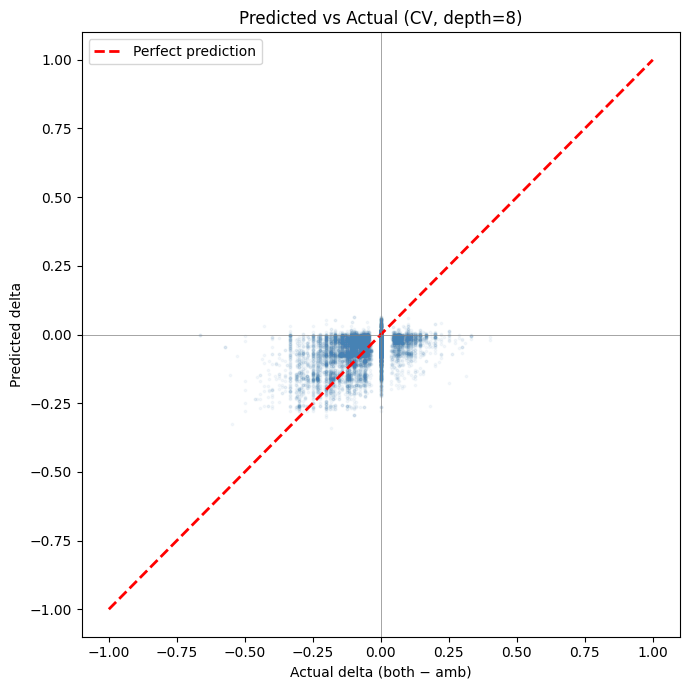

MAE: 0.0379
RMSE: 0.0673


In [6]:
y_pred_reg = cross_val_predict(DecisionTreeRegressor(max_depth=best_d, min_samples_leaf=20, random_state=42), X, delta, cv=10)

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(delta, y_pred_reg, alpha=0.05, s=3, color="steelblue")
ax.plot([-1, 1], [-1, 1], "r--", linewidth=2, label="Perfect prediction")
ax.axhline(0, color="grey", linewidth=0.5)
ax.axvline(0, color="grey", linewidth=0.5)
ax.set_xlabel("Actual delta (both − amb)")
ax.set_ylabel("Predicted delta")
ax.set_title(f"Predicted vs Actual (CV, depth={best_d})")
ax.legend()
plt.tight_layout()
plt.show()

residuals = delta - y_pred_reg
print(f"MAE: {np.abs(residuals).mean():.4f}")
print(f"RMSE: {np.sqrt((residuals**2).mean()):.4f}")